# FashionMNIST — Lightweight CNN with a custom convolutional backbone

**Experiment objective.** Build and evaluate a compact CNN for 10-class FashionMNIST classification, comparing model quality and parameter efficiency against the project's MLP baselines.

**Method.** A custom depthwise-separable convolutional backbone extracts spatial features; global average pooling and a small classification head produce logits for 10 classes. This is a **backbone trained from scratch**, not a pretrained ResNet/MobileNet backbone.

**Evaluation protocol.** Use the same 54,000/6,000/10,000 train/validation/test split as the group project. Select the checkpoint using validation accuracy (validation loss breaks ties). Reserve the official test split for final reporting and do not use test results for hyperparameter selection.

**Reproducibility.** Run cells in order inside the project repository. Every new experiment creates a distinct `outputs/cnn_runs/lan_N/` directory; existing runs and checkpoints are preserved. Each run records its model definition, settings, per-epoch metrics and plots.

## 1. Environment, data and reproducibility

The notebook imports the existing project data-loading and metric utilities rather than duplicating the dataset implementation. The split is stratified with seed 42. Input images are grayscale tensors of shape `(N, 1, 28, 28)`.

**Outputs:** device information and the train/validation/test sample counts. Data preparation must be completed before this notebook is run.

In [1]:
import json, sys, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader

root = Path.cwd().resolve()
while not (root / 'src' / 'data.py').is_file():
    if (root / 'practice_1_fashionmnist' / 'src' / 'data.py').is_file():
        root = root / 'practice_1_fashionmnist'
        break
    if root.parent == root:
        raise FileNotFoundError('Mở notebook trong thư mục project hoặc workspace chứa practice_1_fashionmnist')
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from data import build_loaders
from metrics import evaluate

SETTINGS = dict(seed=42, epochs=40, batch_size=64, lr=0.001,
                weight_decay=1e-4, dropout=0.15, patience=12)
DATA_SETTINGS = dict(seed=42, val_size=0.1, batch_size=SETTINGS['batch_size'])

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

set_seed(SETTINGS['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
train_loader, val_loader, test_loader = build_loaders(DATA_SETTINGS)
print('Device:', device)
print('Train / validation / test:', *(len(x.dataset) for x in (train_loader, val_loader, test_loader)))

Device: cuda
Train / validation / test: 54000 6000 10000


## 2. Architecture — convolutional backbone and classifier

**Backbone:** An initial 3×3 convolution followed by three *depthwise-separable* blocks. Each block uses a spatial depthwise convolution (`groups = input channels`) and a 1×1 pointwise convolution, followed by batch normalization and ReLU. Pooling reduces spatial resolution; global average pooling converts feature maps to a compact vector.

| Stage | Output per image | Purpose |
|---|---|---|
| Input | 1 × 28 × 28 | FashionMNIST grayscale image |
| Stem: Conv2d + BatchNorm + ReLU | 24 × 28 × 28 | Extract local image patterns |
| SepConv 24→48 + MaxPool | 48 × 14 × 14 | Expand channels and downsample |
| SepConv 48→96 + MaxPool | 96 × 7 × 7 | Learn higher-level spatial features |
| SepConv 96→128 + GlobalAvgPool | 128 × 1 × 1 | Compact global representation |
| Head: Flatten + Dropout + Linear | 10 logits | Multiclass classification |

A backbone is a **feature extractor**; it does not imply transfer learning. This experiment trains all backbone weights from scratch. No Softmax layer is added because `CrossEntropyLoss` consumes raw logits.

In [2]:
class SepConv(nn.Module):
    def __init__(self, channels_in, channels_out):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels_in, channels_in, 3, padding=1, groups=channels_in, bias=False),
            nn.Conv2d(channels_in, channels_out, 1, bias=False),
            nn.BatchNorm2d(channels_out),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

class CompactCNN(nn.Module):
    def __init__(self, dropout=0.15):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 24, 3, padding=1, bias=False),
            nn.BatchNorm2d(24), nn.ReLU(inplace=True),
            SepConv(24, 48), nn.MaxPool2d(2),
            SepConv(48, 96), nn.MaxPool2d(2),
            SepConv(96, 128),
            nn.AdaptiveAvgPool2d(1),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(128, 10))

    def forward(self, x):
        return self.head(self.backbone(x))

model = CompactCNN(SETTINGS['dropout']).to(device)
parameters = sum(p.numel() for p in model.parameters())
with torch.no_grad():
    shape = model(torch.zeros(2, 1, 28, 28, device=device)).shape
assert shape == (2, 10)
print('Trainable parameters:', parameters, '| Output shape:', tuple(shape))

Trainable parameters: 21658 | Output shape: (2, 10)


## 3. Model training and checkpoint management

- **Optimizer:** AdamW; **scheduler:** CosineAnnealingLR.
- **Objective:** CrossEntropyLoss for 10 mutually exclusive classes.
- **Checkpoint:** save `best.pt` when validation accuracy improves; break ties using the lower validation loss.
- **Early stopping:** stop after the configured number of consecutive epochs without checkpoint improvement.
- **Run isolation:** create the next available `outputs/cnn_runs/lan_N/` folder **without overwriting** existing runs (including team CNN runs).
- **Saved artifacts:** `config.json`, `metrics.json`, and `best.pt`.

**Note:** online train metrics are measured while weights are updated and may differ from final `eval()` metrics. Test data are not evaluated during training.

In [3]:
set_seed(SETTINGS['seed'])
train_loader, val_loader, test_loader = build_loaders(DATA_SETTINGS)
model = CompactCNN(SETTINGS['dropout']).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=SETTINGS['lr'], weight_decay=SETTINGS['weight_decay'])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=SETTINGS['epochs'])

runs = root / 'outputs' / 'cnn_runs'
runs.mkdir(parents=True, exist_ok=True)
i = 1
while True:
    folder = runs / f'lan_{i}'
    try:
        folder.mkdir()  # Atomic creation; never overwrite a previous experiment
        break
    except FileExistsError:
        i += 1
(folder / 'config.json').write_text(json.dumps(dict(settings=SETTINGS, data=DATA_SETTINGS, parameters=parameters,
    architecture=str(model), selection='max_val_accuracy_then_min_val_loss'), indent=2), encoding='utf-8')
history, best_score, best_epoch, no_improve = [], (-1.0, float('-inf')), 0, 0
start = time.perf_counter()
for epoch in range(1, SETTINGS['epochs'] + 1):
    model.train()
    total_loss, correct = 0., 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
    val = evaluate(model, val_loader, device)
    row = dict(epoch=epoch, train_loss=total_loss / len(train_loader.dataset),
               train_accuracy=correct / len(train_loader.dataset),
               val_loss=val['loss'], val_accuracy=val['accuracy'],
               lr=optimizer.param_groups[0]['lr'])
    history.append(row)
    score = (val['accuracy'], -val['loss'])
    if score > best_score:
        best_score, best_epoch, no_improve = score, epoch, 0
        torch.save(dict(model_state=model.state_dict(), settings=dict(SETTINGS),
             data_config=dict(DATA_SETTINGS), validation=val, epoch=epoch,
             architecture='CompactCNN', parameters=parameters), folder / 'best.pt')
    else:
        no_improve += 1
    print(f"Epoch {epoch:02d}/{SETTINGS['epochs']} | train={row['train_accuracy']:.2%} "
          f"| val={val['accuracy']:.2%} | val_loss={val['loss']:.4f} "
          f"| best={best_epoch} | lr={row['lr']:.6f}", flush=True)
    (folder / 'metrics.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    scheduler.step()
    if no_improve >= SETTINGS['patience']:
        print('Early stopping: validation did not improve')
        break
print(f'Finished: {folder} | best_epoch={best_epoch} | seconds={time.perf_counter()-start:.1f}')

Epoch 01/40 | train=76.77% | val=83.30% | val_loss=0.4734 | best=1 | lr=0.001000
Epoch 02/40 | train=85.48% | val=87.17% | val_loss=0.3647 | best=2 | lr=0.000998
Epoch 03/40 | train=87.18% | val=89.17% | val_loss=0.3129 | best=3 | lr=0.000994
Epoch 04/40 | train=88.28% | val=89.40% | val_loss=0.2989 | best=4 | lr=0.000986
Epoch 05/40 | train=88.97% | val=89.10% | val_loss=0.2907 | best=4 | lr=0.000976
Epoch 06/40 | train=89.31% | val=90.07% | val_loss=0.2743 | best=6 | lr=0.000962
Epoch 07/40 | train=89.94% | val=88.80% | val_loss=0.3156 | best=6 | lr=0.000946
Epoch 08/40 | train=90.17% | val=89.22% | val_loss=0.3023 | best=6 | lr=0.000926
Epoch 09/40 | train=90.64% | val=90.62% | val_loss=0.2718 | best=9 | lr=0.000905
Epoch 10/40 | train=90.85% | val=90.17% | val_loss=0.2782 | best=9 | lr=0.000880
Epoch 11/40 | train=91.14% | val=91.02% | val_loss=0.2497 | best=11 | lr=0.000854
Epoch 12/40 | train=91.40% | val=90.98% | val_loss=0.2476 | best=11 | lr=0.000825
Epoch 13/40 | train=91.56%

## 4. Reload and evaluate the selected checkpoint

Reload `best.pt` explicitly before reporting results; do not evaluate the final epoch's in-memory weights by accident. Both training and validation evaluation use `model.eval()` and unaugmented inputs from the project's loader, where configured.

**Artifacts:** `result.json` containing sample counts, accuracy, loss, and best epoch. Validation metrics should agree with the saved checkpoint metadata.

In [4]:
saved = torch.load(folder / 'best.pt', map_location=device, weights_only=True)
model = CompactCNN(saved['settings']['dropout']).to(device)
model.load_state_dict(saved['model_state'])
model.eval()
train_eval = DataLoader(train_loader.dataset, batch_size=256, shuffle=False)
scores = {'train': evaluate(model, train_eval, device),
          'validation': evaluate(model, val_loader, device)}
print('Best epoch:', saved['epoch'], '| Parameters:', saved['parameters'])
print(pd.DataFrame(scores).T.to_string())
assert abs(scores['validation']['accuracy'] - saved['validation']['accuracy']) < 1e-10
(folder / 'result.json').write_text(json.dumps(dict(scores=scores, best_epoch=saved['epoch']), indent=2), encoding='utf-8')

Best epoch: 28 | Parameters: 21658
                loss  accuracy    count
train       0.134369  0.953704  54000.0
validation  0.220418  0.923333   6000.0


275

## 5. Training diagnostics and validation error analysis

The learning curves help reveal overfitting or underfitting. Training curves reflect online batches, whereas validation is evaluated after each epoch. The vertical line shows the selected checkpoint epoch.

For the confusion matrix, **rows represent true labels** and **columns represent predictions**. This matrix identifies class-level error patterns; it is computed from validation, not test.

**Artifacts:** `curves.png`, `confusion_validation.png`, and `confusion_validation.json`.

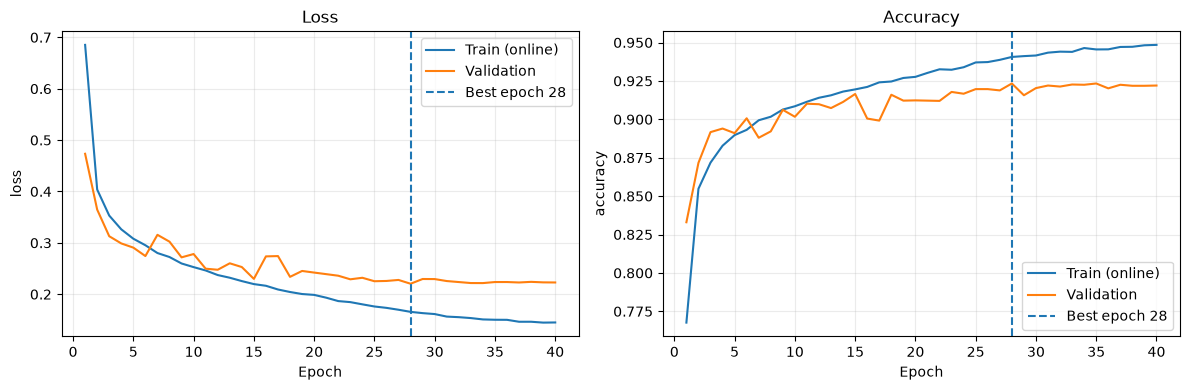

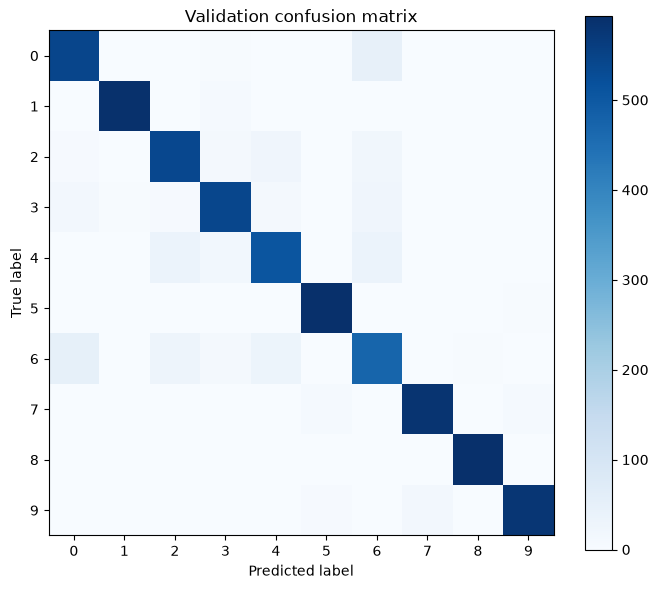

355

In [5]:
df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, axis in [('loss', axes[0]), ('accuracy', axes[1])]:
    axis.plot(df.epoch, df['train_' + key], label='Train (online)')
    axis.plot(df.epoch, df['val_' + key], label='Validation')
    axis.axvline(best_epoch, linestyle='--', label=f'Best epoch {best_epoch}')
    axis.set(title=key.title(), xlabel='Epoch', ylabel=key)
    axis.grid(alpha=.25); axis.legend()
fig.tight_layout(); fig.savefig(folder / 'curves.png', dpi=130); plt.show()

confusion = torch.zeros(10, 10, dtype=torch.int64)
with torch.no_grad():
    for images, labels in val_loader:
        pred = model(images.to(device)).argmax(1).cpu()
        for true, guess in zip(labels, pred): confusion[int(true), int(guess)] += 1
assert confusion.sum().item() == len(val_loader.dataset)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(confusion.numpy(), cmap='Blues')
ax.set(xlabel='Predicted label', ylabel='True label', title='Validation confusion matrix')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(folder / 'confusion_validation.png', dpi=130); plt.show()
(folder / 'confusion_validation.json').write_text(json.dumps(confusion.tolist()), encoding='utf-8')

## 6. Comparison with MLP baselines and final test

Read the group's recorded MLP validation results directly from `outputs/run_review.json`; no baseline numbers are invented. Compare validation accuracy/loss and model size, while noting different architectures and training budgets.

`RUN_FINAL_TEST` is **disabled by default**. Enable it only when the model has been selected and no further model selection is planned. Since previous work may already have used test scores, document that limitation when writing conclusions.

When the flag is enabled, the **selected `best.pt`** is evaluated and its test metrics are appended to `result.json`.

In [6]:
review_path = root / 'outputs' / 'run_review.json'
if review_path.exists():
    review = json.loads(review_path.read_text(encoding='utf-8'))
    entries = []
    for run in review.get('runs', []):
        if run.get('run') in {'lan_10', 'lan_11', 'lan_12'}:
            val = run.get('splits', {}).get('validation', {})
            entries.append(dict(model='MLP ' + run['run'], parameters=None,
                                val_accuracy=val.get('accuracy'), val_loss=val.get('loss')))
    entries.append(dict(model='CNN ' + folder.name, parameters=parameters,
                        val_accuracy=scores['validation']['accuracy'], val_loss=scores['validation']['loss']))
    print(pd.DataFrame(entries).to_string(index=False))
else:
    print('Không thấy run_review.json: chỉ báo cáo CNN, không tự tạo số liệu MLP.')

RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    scores['test'] = evaluate(model, test_loader, device)
    print('FINAL TEST:', scores['test'])
    (folder / 'result.json').write_text(json.dumps(dict(scores=scores, best_epoch=saved['epoch']), indent=2), encoding='utf-8')

     model  parameters  val_accuracy  val_loss
MLP lan_10         NaN      0.913333  0.277989
MLP lan_11         NaN      0.914833  0.308205
MLP lan_12         NaN      0.917333  0.299211
 CNN lan_3     21658.0      0.923333  0.220418


## 7. Visualize learned backbone features

Inspect feature maps for one validation image. Each channel is an activation map learned by the backbone; these activations are **not** class probabilities or proof that a particular semantic feature was learned. Global average pooling produces 1×1 features, so this example captures activations *before* global pooling.

This qualitative visualization supports explanation of spatial feature extraction but does not replace quantitative metrics.

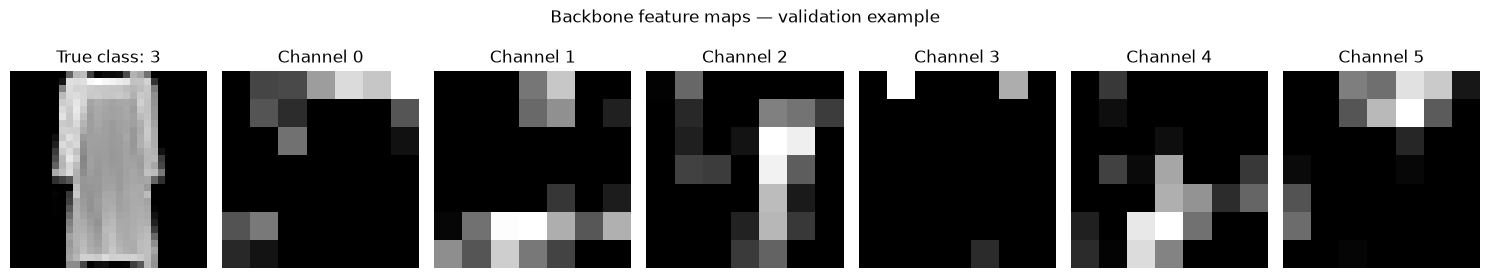

In [8]:
# Inspect feature maps immediately before global average pooling.
image, label = val_loader.dataset[0]
with torch.no_grad():
    activations = model.backbone[:-1](image.unsqueeze(0).to(device)).cpu()[0]
fig, axes = plt.subplots(1, 7, figsize=(15, 3))
axes[0].imshow(image[0], cmap='gray')
axes[0].set_title(f'True class: {int(label)}')
axes[0].axis('off')
for channel, ax in enumerate(axes[1:]):
    ax.imshow(activations[channel], cmap='gray')
    ax.set_title(f'Channel {channel}')
    ax.axis('off')
fig.suptitle('Backbone feature maps — validation example')
fig.tight_layout()
fig.savefig(folder / 'backbone_features.png', dpi=130)
plt.show()

Nếu muốn tối ưu tiếp thì có thể thử:

    Learning rate và scheduler: điều chỉnh tốc độ hội tụ, có thể thử giảm learning rate hoặc thay lịch giảm LR.

    Dropout và weight decay: điều chỉnh regularization để cân bằng train accuracy và khả năng tổng quát hóa.

    Số channels / residual blocks: tăng khả năng học đặc trưng, nhưng sẽ tăng số parameters.

    Data augmentation: thử xoay/dịch ảnh nhẹ để cải thiện khả năng tổng quát hóa.

Lưu ý, tăng train accuracy không đảm bảo test accuracy tăng. Nên dùng validation để chọn cấu hình, không tuning trực tiếp theo test.

Tui giữ kiến trúc hiện tại vì đã vượt MLP trên validation, số tham số thấp và kết quả tương đối ổn định. Notebook có lưu metrics và checkpoint theo từng run để tiện so sánh.
